## Load the image list

In [1]:
from pathlib import Path
import cv2, numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns

DATA = Path("../data")   # the notebook lives in notebook/, so go up one level

rows = []
for split in ["train", "test"]:
    for img in (DATA / split).glob("*/*.jpg"):
        rows.append({"path": img, "split": split,
                     "label": img.parent.name,              # folder name = class
                     "drawing": img.name.split("_")[0]})    # "spiral_0068-1.jpg" -> "spiral"
df = pd.DataFrame(rows)
df.groupby(["split", "label", "drawing"]).size().unstack()

drawing          meander  spiral
split label                     
test  healthy         16      16
      parkinson       60      60
train healthy         56      56
      parkinson      236     236

# Visualization

## Class balance

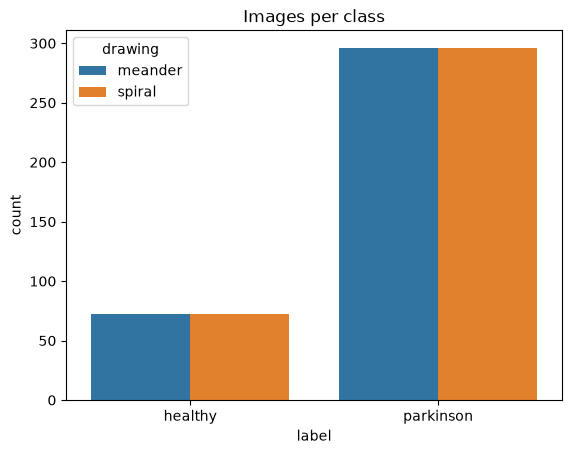

In [2]:
sns.countplot(data=df, x="label", hue="drawing")
plt.title("Images per class"); plt.show()

## The preprocessing function

In [3]:
IMG_SIZE = 256

def separate_layers(path):
    """Resize the scan and split it into the patient's pen stroke (blue) and the printed template (black)."""
    img = cv2.resize(cv2.imread(str(path)), (IMG_SIZE, IMG_SIZE))
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    pen      = cv2.inRange(hsv, (100, 80, 50), (140, 255, 255))   # blue hue, fairly saturated
    template = cv2.inRange(hsv, (0, 0, 0),    (180, 255, 90))     # any hue, but dark
    return img, pen, template

## Check that the masks look right 

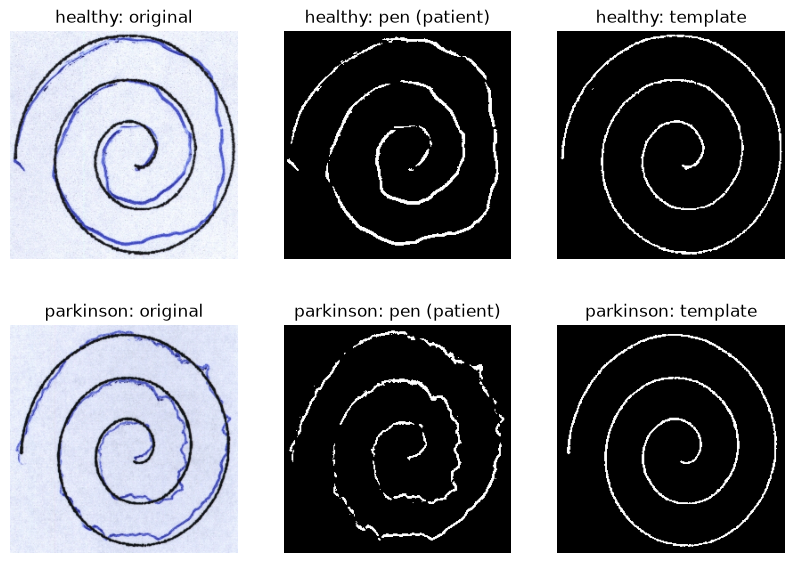

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(10, 7))
for row, label in enumerate(["healthy", "parkinson"]):
    path = df[(df.label == label) & (df.drawing == "spiral")].path.iloc[0]
    img, pen, tpl = separate_layers(path)
    for ax, im, title in zip(axes[row], [img[..., ::-1], pen, tpl], ["original", "pen (patient)", "template"]):
        ax.imshow(im, cmap="gray"); ax.set_title(f"{label}: {title}"); ax.axis("off")
plt.show()

## The engineered features

In [ ]:
def extract_features(path):
    _, pen, tpl = separate_layers(path)                      # pen = patient's ink, tpl = printed template
    pen_px, tpl_px = (pen > 0).sum(), (tpl > 0).sum()        # number of ink pixels / template pixels

    dist_to_template = cv2.distanceTransform(255 - tpl, cv2.DIST_L2, 3)  # each pixel's distance to the template line
    dev = dist_to_template[pen > 0] if pen_px else np.zeros(1)            # distances for the patient's ink pixels only

    n, _, stats, _ = cv2.connectedComponentsWithStats(pen)   # find separate ink pieces
    areas = stats[1:, cv2.CC_STAT_AREA]                      # size of each piece (index 0 = background, skipped)

    thickness_map = cv2.distanceTransform(pen, cv2.DIST_L2, 3)  # inside the ink: distance to the ink's edge (≈ half line width)
    thick = thickness_map[pen > 0] if pen_px else np.zeros(1)   # thickness values along the stroke

    near_pen = cv2.dilate(pen, np.ones((5, 5), np.uint8)) > 0   # widen the ink by 2 px in every direction

    return {
        "ink_ratio":         pen_px / max(tpl_px, 1),        # amount of ink vs template (pen pressure / line weight)
        "deviation":         dev.mean(),                     # average distance off the line
        "fragments":         int((areas >= 5).sum()),        # number of broken pieces (ignore specks < 5 px)
        "deviation_p90":     np.percentile(dev, 90),         # how far the worst 10% of the stroke strays (big tremor swings)
        "deviation_std":     dev.std(),                      # consistency: steady vs erratic distance from the line
        "thickness_mean":    thick.mean(),                   # average line thickness (pressure)
        "thickness_std":     thick.std(),                    # pressure variation along the stroke
        "largest_piece":     areas.max() / max(pen_px, 1) if len(areas) else 0,  # share of ink in the biggest continuous piece
        "template_coverage": (near_pen & (tpl > 0)).sum() / max(tpl_px, 1),      # % of the template the patient actually traced
    }
    
feats = pd.DataFrame([extract_features(p) for p in df.path])   # run the function on every image -> one row of features each
df = df.drop(columns=feats.columns, errors="ignore")           # remove old feature columns if the cell was run before
df = pd.concat([df, feats], axis=1)                            # attach the feature columns to the image table
df.head()                                                      # check: ink_ratio, deviation, etc. should appear

## Visualization and interpretation

ValueError: Could not interpret value `ink_ratio` for `y`. An entry with this name does not appear in `data`.

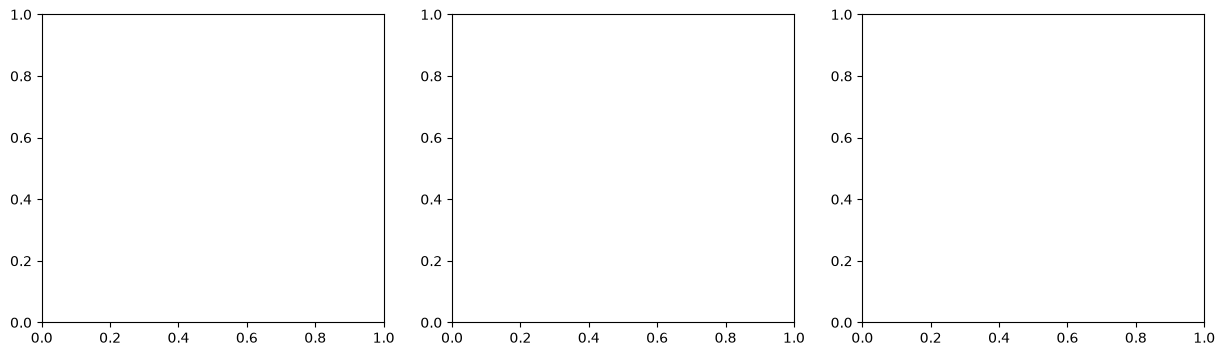

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, f in zip(axes, ["ink_ratio", "deviation", "fragments"]):
    sns.boxplot(data=df, x="drawing", y=f, hue="label", ax=ax); ax.set_title(f)
plt.tight_layout(); plt.savefig("../reports/figures/features.png", dpi=120); plt.show()

df.groupby("label")[["ink_ratio", "deviation", "fragments"]].median()

## targets and person IDs


In [ ]:
df["y"] = (df.label == "parkinson").astype(int)            # target the model predicts: 1 = Parkinson's, 0 = healthy
df["is_spiral"] = (df.drawing == "spiral").astype(int)      # drawing type as a number so the model can use it
df["person"] = df.label + "_" + df.path.apply(              # rebuild the person ID from the file name...
    lambda p: p.stem.split("_")[1].split("-")[0])           # ..."spiral_0068-1" -> "0068" -> "healthy_0068"

split train into fit, validation and new-batch, by person

In [ ]:
from sklearn.model_selection import StratifiedGroupKFold

train_df = df[df.split == "train"].reset_index(drop=True)  # training images only
test_df  = df[df.split == "test"].reset_index(drop=True)   # test set: never touched until final evaluation

sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)  # 5 groups of people, same class ratio in each
train_df["role"] = "fit"                                    # by default an image is used to fit the model
for fold, (_, idx) in enumerate(sgkf.split(train_df, train_df.y, groups=train_df.person)):
    if fold == 0: train_df.loc[idx, "role"] = "val"         # 1/5 of people: validation (watch the CNN while it trains)
    if fold == 1: train_df.loc[idx, "role"] = "new_batch"   # 1/5 of people: held back to simulate new clinic data

# Save which image has which role so the API's retraining code can reuse it later
train_df.assign(file=train_df.path.apply(lambda p: f"{p.parent.name}/{p.name}"))[["file", "role"]] \
    .to_csv("../data/train_roles.csv", index=False)         # e.g. "healthy/spiral_0068-1.jpg,fit"

# Copy the new-batch images into a folder you'll upload in the demo
import shutil
for p in train_df[train_df.role == "new_batch"].path:      # loop over the held-back images
    dest = Path("../data/retrain_batch") / p.parent.name / p.name   # keep the label folder: healthy/ or parkinson/
    dest.parent.mkdir(parents=True, exist_ok=True)          # create the folder if it doesn't exist yet
    shutil.copy(p, dest)                                    # copy rather than move, so re-running the notebook still works

train_df.groupby(["role", "label"]).size().unstack()        # show the counts for each role and class

label,healthy,parkinson
role,,
fit,64,280
new_batch,24,96
val,24,96


## one evaluation function for every model

In [ ]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay)

def evaluate(name, y_true, y_prob, threshold=0.5):
    y_pred = (y_prob >= threshold).astype(int)              # turn probabilities into 0/1 decisions
    results = {
        "model": name,
        "accuracy":    accuracy_score(y_true, y_pred),      # % of all predictions that were correct
        "precision":   precision_score(y_true, y_pred),     # of those flagged Parkinson's, % that really were
        "recall":      recall_score(y_true, y_pred),        # of real Parkinson's cases, % we caught (sensitivity)
        "specificity": recall_score(y_true, y_pred, pos_label=0),  # of healthy people, % correctly cleared
        "f1":          f1_score(y_true, y_pred),            # balance of precision and recall
        "roc_auc":     roc_auc_score(y_true, y_prob),       # how well it ranks patients above healthy people, at any threshold
    }
    fig, ax = plt.subplots(1, 2, figsize=(10, 4))           # two plots side by side
    ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred),
                           display_labels=["healthy", "parkinson"]).plot(ax=ax[0], colorbar=False)  # the error table
    RocCurveDisplay.from_predictions(y_true, y_prob, ax=ax[1])  # ROC curve: true-positive rate vs false-positive rate
    ax[0].set_title(f"{name}: confusion matrix"); ax[1].set_title(f"{name}: ROC curve")
    plt.tight_layout(); plt.savefig(f"../reports/figures/eval_{name}.png", dpi=120); plt.show()
    return results

## Model A, Random Forest on the engineered features, with tuning

Best settings: {'max_depth': 5, 'min_samples_leaf': 1, 'n_estimators': 100} | CV ROC-AUC: 0.876


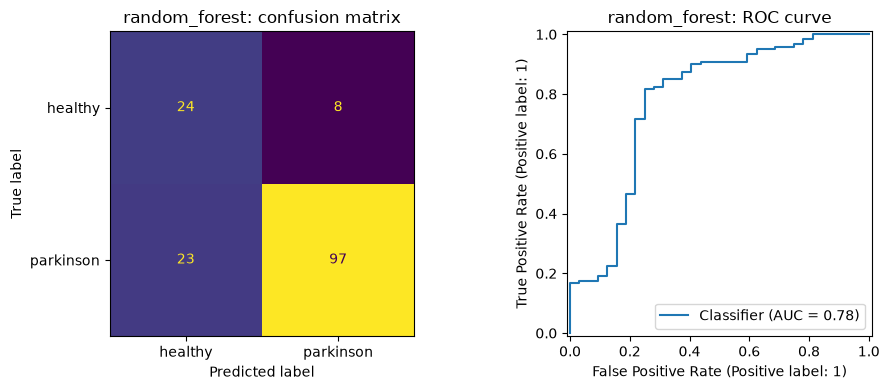

{'model': 'random_forest',
 'accuracy': 0.7960526315789473,
 'precision': 0.9238095238095239,
 'recall': 0.8083333333333333,
 'specificity': 0.75,
 'f1': 0.8622222222222222,
 'roc_auc': 0.7763020833333334}

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV
import joblib

FEATURES = ["ink_ratio", "deviation", "fragments", "is_spiral"]   # the model's inputs
base = train_df[train_df.role != "new_batch"]               # v1 trains on fit + val people (new batch held back)

grid = GridSearchCV(
    RandomForestClassifier(class_weight="balanced", random_state=42),  # "balanced" = healthy errors weigh ~4x more
    param_grid={"n_estimators": [100, 300],                 # number of trees
                "max_depth": [3, 5, None],                  # how deep each tree may grow (shallow = less overfitting)
                "min_samples_leaf": [1, 5]},                # minimum images per leaf (bigger = smoother)
    cv=StratifiedGroupKFold(n_splits=5),                    # cross-validation that also keeps each person in one fold
    scoring="roc_auc")                                      # pick the settings with the best ROC-AUC
grid.fit(base[FEATURES], base.y, groups=base.person)        # try all 12 combinations x 5 folds
print("Best settings:", grid.best_params_, "| CV ROC-AUC:", round(grid.best_score_, 3))

rf = grid.best_estimator_                                   # the forest refit on all base data with the best settings
rf_results = evaluate("random_forest", test_df.y, rf.predict_proba(test_df[FEATURES])[:, 1])  # column 1 = P(Parkinson's)
rf_results

## Model B, a small CNN trained from scratch on pen masks

In [ ]:
import os; os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"        # hide TensorFlow's noisy startup logs
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

CNN_SIZE = 128                                              # small images, so training is fast on CPU

def load_pen_mask(path):
    _, pen, _ = separate_layers(path)                       # reuse the cell 3 function: keep only the patient's ink
    pen = cv2.resize(pen, (CNN_SIZE, CNN_SIZE), interpolation=cv2.INTER_AREA)  # INTER_AREA = good for shrinking
    return pen.astype("float32") / 255.0                    # scale pixels from 0–255 to 0–1

def to_arrays(frame):
    X = np.stack([load_pen_mask(p) for p in frame.path])[..., None]  # shape (n, 128, 128, 1): 1 = one colour channel
    return X, frame.y.values

X_fit, y_fit = to_arrays(train_df[train_df.role == "fit"])  # images the CNN learns from
X_val, y_val = to_arrays(train_df[train_df.role == "val"])  # images it is checked on each epoch
X_test, y_test = to_arrays(test_df)                         # final exam

tf.random.set_seed(42)                                      # repeatable results
cnn = keras.Sequential([
    layers.Input((CNN_SIZE, CNN_SIZE, 1)),
    layers.RandomFlip("horizontal_and_vertical"),           # augmentation: a mirrored spiral is still a spiral
    layers.RandomRotation(0.1),                             # ...slightly rotated (±36°) is still valid
    layers.RandomZoom(0.1),                                 # ...slightly zoomed too. Only active during training
    layers.Conv2D(16, 3, activation="relu", padding="same"), layers.MaxPooling2D(),   # detects small edges and strokes
    layers.Conv2D(32, 3, activation="relu", padding="same"), layers.MaxPooling2D(),   # combines them into wiggles and corners
    layers.Conv2D(64, 3, activation="relu", padding="same"), layers.MaxPooling2D(),   # larger shapes: jagged segments
    layers.Conv2D(128, 3, activation="relu", padding="same"),                         # high-level tremor patterns
    layers.GlobalAveragePooling2D(),                        # average each pattern map into one number (few parameters)
    layers.Dropout(0.4),                                    # randomly switch off 40% of neurons to reduce overfitting
    layers.Dense(1, activation="sigmoid"),                  # output: probability of Parkinson's (0–1)
])
cnn.compile(optimizer=keras.optimizers.Adam(1e-3),          # Adam optimiser, learning rate 0.001
            loss="binary_crossentropy",                     # standard loss for yes/no classification
            metrics=[keras.metrics.AUC(name="auc")])        # track ROC-AUC while training

n_h, n_p = (y_fit == 0).sum(), (y_fit == 1).sum()          # count healthy and Parkinson's images
class_weight = {0: len(y_fit) / (2 * n_h), 1: len(y_fit) / (2 * n_p)}   # rarer class (healthy) gets a bigger weight

history = cnn.fit(X_fit, y_fit, validation_data=(X_val, y_val),
                  epochs=60, batch_size=32, class_weight=class_weight,   # more epochs: it learns slowly at first
                  callbacks=[keras.callbacks.EarlyStopping(
                      monitor="val_auc", mode="max", patience=15,        # wait longer before giving up
                      restore_best_weights=True)])                       # still roll back to the best epoch
cnn.summary()                                               # print the layers and parameter counts

Epoch 1/60
11/11 ━━━━━━━━━━━━━━━━━━━━ 8s 375ms/step - auc: 0.4096 - loss: 0.7013 - val_auc: 0.5434 - val_loss: 0.7143
Epoch 2/60
11/11 ━━━━━━━━━━━━━━━━━━━━ 4s 339ms/step - auc: 0.5371 - loss: 0.6929 - val_auc: 0.5677 - val_loss: 0.7058
Epoch 3/60
11/11 ━━━━━━━━━━━━━━━━━━━━ 4s 331ms/step - auc: 0.5271 - loss: 0.6926 - val_auc: 0.5645 - val_loss: 0.7055
Epoch 4/60
11/11 ━━━━━━━━━━━━━━━━━━━━ 4s 391ms/step - auc: 0.5078 - loss: 0.6934 - val_auc: 0.5686 - val_loss: 0.7036
Epoch 5/60
11/11 ━━━━━━━━━━━━━━━━━━━━ 4s 366ms/step - auc: 0.5638 - loss: 0.6920 - val_auc: 0.6029 - val_loss: 0.7030
Epoch 6/60
11/11 ━━━━━━━━━━━━━━━━━━━━ 4s 346ms/step - auc: 0.5085 - loss: 0.6931 - val_auc: 0.6801 - val_loss: 0.7086
Epoch 7/60
11/11 ━━━━━━━━━━━━━━━━━━━━ 4s 370ms/step - auc: 0.5549 - loss: 0.6921 - val_auc: 0.6899 - val_loss: 0.7138
Epoch 8/60
11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 415ms/step - auc: 0.5825 - loss: 0.6922 - val_auc: 0.7220 - val_loss: 0.7126
Epoch 9/60
11/11 ━━━━━━━━━━━━━━━━━━━━ 4s 399ms/step - au

KeyboardInterrupt: 

##  learning curves, then test evaluation

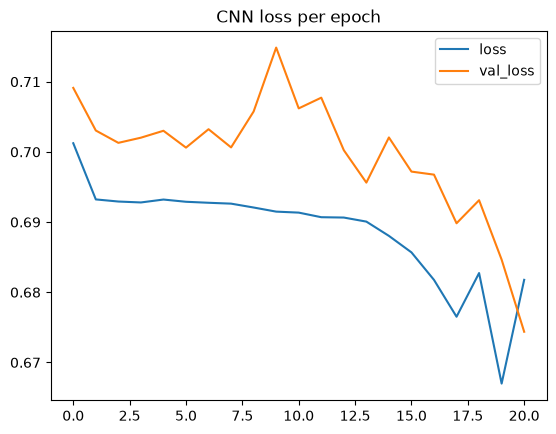

5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 108ms/step


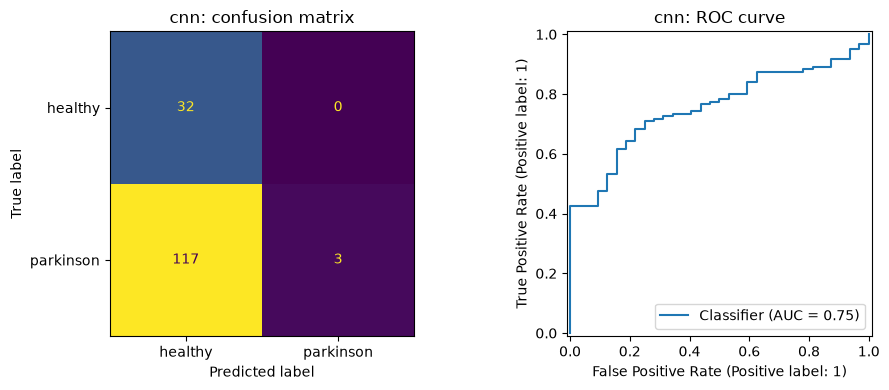

{'model': 'cnn',
 'accuracy': 0.23026315789473684,
 'precision': 1.0,
 'recall': 0.025,
 'specificity': 1.0,
 'f1': 0.04878048780487805,
 'roc_auc': 0.7544270833333332}

In [ ]:
from sklearn.metrics import roc_curve
val_prob = cnn.predict(X_val).ravel()                       # CNN scores on the validation people
fpr, tpr, thresholds = roc_curve(y_val, val_prob)           # every possible cut-off and its error rates
best_t = thresholds[np.argmax(tpr - fpr)]                   # Youden's J: the cut-off that best balances recall and specificity
print("Chosen threshold:", round(best_t, 3))
cnn_results = evaluate("cnn", y_test, cnn.predict(X_test).ravel(), threshold=best_t)  # test the chosen cut-off on unseen data

##  compare and save both models

In [ ]:
comparison = pd.DataFrame([rf_results, cnn_results]).set_index("model").round(3)   # one row per model
display(comparison)                                         # the table for your README and video

joblib.dump(rf, "../models/neurotrace_rf_v1.pkl")           # save the forest (the rubric accepts .pkl)
cnn.save("../models/neurotrace_cnn_v1.h5")                  # save the CNN as .h5 (ignore the "legacy format" warning)
comparison.to_csv("../reports/model_comparison.csv")        # keep the numbers for the dashboard later

,accuracy,precision,recall,specificity,f1,roc_auc
model,,,,,,
random_forest,0.796,0.924,0.808,0.75,0.862,0.776
cnn,0.230,1.000,0.025,1.00,0.049,0.754
